# Application of QMCCBO: A two-dimensional data-driven model for traffic flow in highways

### Data Set: Vehicle Trajectory Dataset from Drone Videos by Moritz Berghausa, Serge Lambertya, Jörg Ehlersa, Eszter Kallóa, Markus Oeser


# Off-ramp data set

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np
import torch
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from matplotlib.patches import Rectangle, ConnectionPatch


# Select recording
recording = 1  # XX in XX_tracks.csv
data_path = Path("data")

recording_str = f"{recording:02d}"

tracks = pd.read_csv(data_path / f"{recording_str}_tracks.csv")
tracks_meta = pd.read_csv(data_path / f"{recording_str}_tracksMeta.csv")
recording_meta = pd.read_csv(data_path / f"{recording_str}_recordingMeta.csv")
highway_image = Image.open(data_path / f"{recording_str}_highway.png")

C:\Users\jheieck\AppData\Local\Temp\ipykernel_19992\3934682192.py:2: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


In [4]:
print(recording_meta.iloc[0])

id                                     1
frameRate                             25
locationId                             2
speedLimit                          -1.0
month                             9.2017
weekDay                              Tue
startTime                          08:38
duration                          901.56
totalDrivenDistance            418549.19
totalDrivenTime                 13908.12
numVehicles                         1047
numCars                              863
numTrucks                            184
upperLaneMarkings       8.51;12.59;16.43
lowerLaneMarkings      21.00;24.96;28.80
Name: 0, dtype: object


In [ ]:
meta = recording_meta.iloc[0]

# Additional information
num_frames = tracks["frame"].max() - tracks["frame"].min() + 1

upper_markings = [float(x) for x in meta["upperLaneMarkings"].split(";")]
lower_markings = [float(x) for x in meta["lowerLaneMarkings"].split(";")]

num_upper_lanes = len(upper_markings) - 1
num_lower_lanes = len(lower_markings) - 1

min_speed = tracks_meta["minXVelocity"].min() * 3.6
max_speed = tracks_meta["maxXVelocity"].max() * 3.6

L = tracks["x"].max() - tracks["x"].min()  # [m]

print("=" * 60)
print(f"Recording {meta['id']}")
print("=" * 60)

print(f"Month:                    {meta['month']}")
print(f"Weekday:                  {meta['weekDay']}")
print(f"Start time:               {meta['startTime']}")
print(f"Duration:                 {meta['duration']:.1f} s")
print(f"Number of frames:         {num_frames}")

print()

print(f"Number of vehicles:       {meta['numVehicles']}")
print(f"Cars:                     {meta['numCars']}")
print(f"Trucks:                   {meta['numTrucks']}")

print()

print(f"Frame rate:               {meta['frameRate']} Hz")
print(f"Speed limit:              {meta['speedLimit']*3.6:.1f} km/h")
print(f"Observed speed range:     {min_speed:.1f} – {max_speed:.1f} km/h")

print()

print(f"Upper direction lanes:    {num_upper_lanes} (vehicles drive left)")
print(f"Lower direction lanes:    {num_lower_lanes} (vehicles drive right)")
print(f"Total driving lanes:      {num_upper_lanes + num_lower_lanes}")
print(f"Road section length:      {L:.1f} m")

Recording 1
Month:                    9.2017


KeyError: 'day'

### fundamental diagrams (choose sepcifiv direction or both directions)

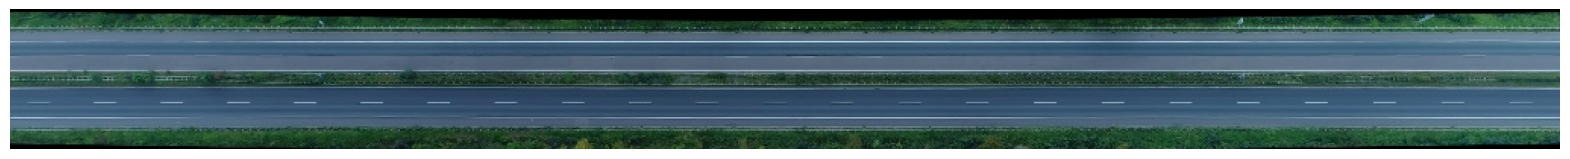

In [3]:
plt.figure(figsize=(20,10))
plt.imshow(highway_image)
plt.axis("off")
#plt.title(f"Recording {recording_str}")
plt.savefig(f"recording_{recording_str}.png", dpi=300, bbox_inches="tight", pad_inches=0)
plt.show()

### fundamental diagrams (choose sepcifiv direction or both directions)

In [4]:
direction_choice = 'both'  # choose between 1, 2 and "both"

In [5]:
# transform velocity [m/s] to [km/h]
tracks["vx_kmh"] = np.abs(tracks["xVelocity"]) * 3.6
tracks["vy_kmh"] = tracks["yVelocity"] * 3.6

# add driving direction information
tracks = tracks.merge(tracks_meta[["id", "drivingDirection"]], on="id", how="left")

# select desired driving direction(s)
if direction_choice == "both":
    tracks_selected = tracks.copy()
elif direction_choice in [1, 2]:
    tracks_selected = tracks[tracks["drivingDirection"] == direction_choice].copy()
else:
    raise ValueError("direction_choice must be 'both', 1 or 2.")

# determine number of driving lanes
number_lanes = tracks_selected["laneId"].nunique()

print(f"Driving direction : {direction_choice}")
print(f"Driving lanes     : {number_lanes}")

Driving direction : both
Driving lanes     : 4


In [6]:
# determine density
L = tracks_selected["x"].max() - tracks_selected["x"].min()  # road length [m]
tracks_selected["t_bin"] = np.floor(tracks_selected["frame"] / meta["frameRate"])  # second = frame [frames] / framerate [frames/second]
N = tracks_selected.groupby("t_bin")["id"].nunique()
rho = N / (L / 1000)  # \tilde{rho}(t_k): density [vehicle/km] per time 

# determine average velocity and fluxes
ux_kmh = tracks_selected.groupby("t_bin")["vx_kmh"].mean()  # \tilde{u}^x(t_k): average velocity [km/h] in x-direction per time 
uy_kmh = tracks_selected.groupby("t_bin")["vy_kmh"].mean()  # \tilde{u}^y(t_k): aberage velocity [km/h] in y-direction per time
qx = rho * ux_kmh  # \tilde{q}^x(t_k): flux [vehicle/h] in x-direction per time 
qy = rho * uy_kmh  # \tilde{q}^y(t_k): flux [vehicle/h] in x-direction per time 

# determine moving mean of densitiy, flux and average velocity
window_value = 60*3
rho_data = rho.rolling(window=window_value, min_periods=window_value).mean()
qx_data = qx.rolling(window=window_value, min_periods=window_value).mean()
qy_data = qy.rolling(window=window_value, min_periods=window_value).mean()

# neglect non-numerical values
mask = (rho_data.notna() & qx_data.notna() & qy_data.notna())  
rho_data = rho_data[mask]
qx_data = qx_data[mask]
qy_data = qy_data[mask]
ux_data = qx_data / rho_data 
uy_data = qy_data / rho_data

# transform to torch-tensor for (QMC)CBO application
rho_torch = torch.tensor(rho_data.to_numpy(), dtype=torch.float32)
qx_torch = torch.tensor(qx_data.to_numpy(), dtype=torch.float32)
qy_torch = torch.tensor(qy_data.to_numpy(), dtype=torch.float32)
ux_torch = qx_torch / rho_torch
uy_torch = qy_torch / rho_torch

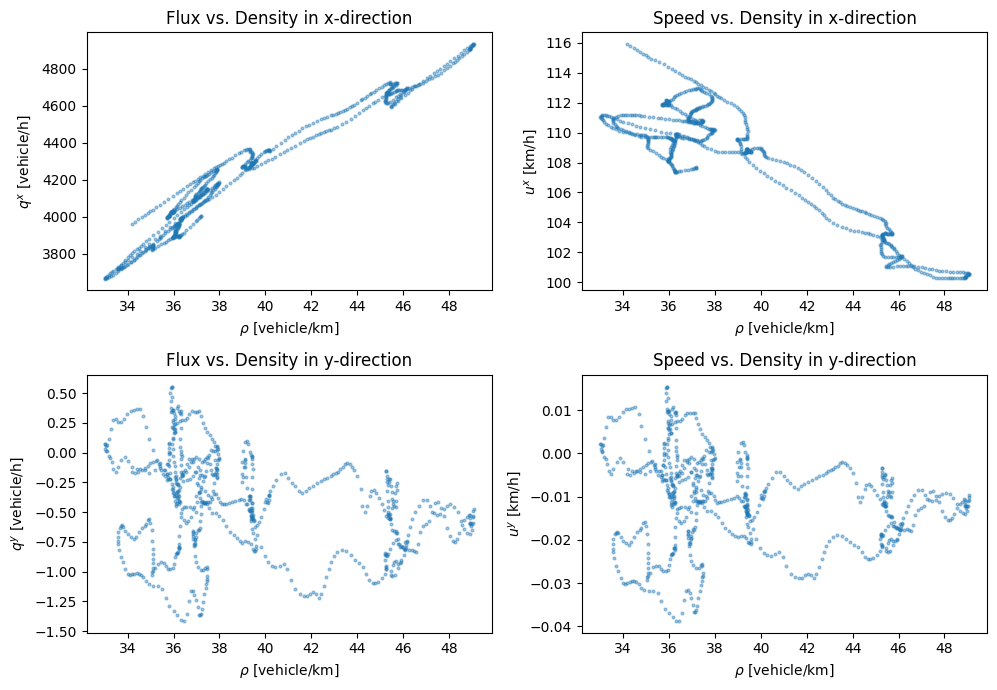

In [7]:
# plotting fundamental diagrams
fig, ax = plt.subplots(2, 2, figsize=(10,7))

# Flux x-direction
ax[0,0].scatter(rho_data, qx_data, s=4, alpha=0.4)
ax[0,0].set_title("Flux vs. Density in x-direction")
ax[0,0].set_xlabel(r"$\rho$ [vehicle/km]")
ax[0,0].set_ylabel(r"$q^x$ [vehicle/h]")

# Speed x-direction
ax[0,1].scatter(rho_data, ux_data, s=4, alpha=0.4)
ax[0,1].set_title("Speed vs. Density in x-direction")
ax[0,1].set_xlabel(r"$\rho$ [vehicle/km]")
ax[0,1].set_ylabel(r"$u^x$ [km/h]")

# Flux y-direction
ax[1,0].scatter(rho_data, qy_data, s=4, alpha=0.4)
ax[1,0].set_title("Flux vs. Density in y-direction")
ax[1,0].set_xlabel(r"$\rho$ [vehicle/km]")
ax[1,0].set_ylabel(r"$q^y$ [vehicle/h]")

# Speed y-direction
ax[1,1].scatter(rho_data, uy_data, s=4, alpha=0.4)
ax[1,1].set_title("Speed vs. Density in y-direction")
ax[1,1].set_xlabel(r"$\rho$ [vehicle/km]")
ax[1,1].set_ylabel(r"$u^y$ [km/h]")

plt.tight_layout()
plt.savefig(f"images/fundamental_diagrams_{recording}_dircetion_{direction_choice}.png", dpi=300, bbox_inches="tight")
plt.show()

### Model and objective functions

In [8]:
rho_max = number_lanes / 7.5 * 1000  # maxmial density [vehicle/km]

# Model functions

# Scipy optimization
# INPUT: - rho (1xM numpy-vector): density rho for any observation (data point)
#        - lam (scalar): lambda parameter
#        - p (scalar): p parameter
# OUTPUT: - prediction (1xM numpy-vector): base shape function g_{lam,p}(rho), eq. (3.38)
def g_shape_numpy(rho, lam, p):

    d1 = np.sqrt(1 + (lam*p)**2)
    d2 = np.sqrt(1 + (lam*(1-p))**2)
    d3 = lam*(rho/rho_max - p)
    return d1 + (d2-d1)*(rho/rho_max) - np.sqrt(1 + d3**2)

# INPUT: - alpha (scalar): alpha parameter
#        - lam (scalar): lambda parameter
#        - p (scalar): p parameter
#        - rho (1xM numpy-vector): density rho for any obersvation (data point)
# OUTPUT: - prediction (1xM numpy-vector): approximated flux for model parameter combination and observed data point (column)
def qx_model_numpy(rho, alpha, lam, p):
    return alpha * g_shape_numpy(rho, lam, p)

# NEW y-model (eq. 3.13): q^y = (rho/rho_max - p) * q_{alpha,lam,p}(rho)
def qy_model_numpy(rho, alpha, lam, p):
    return (rho/rho_max - p) * qx_model_numpy(rho, alpha, lam, p)

# (QMC)CBO
# INPUT: - lam (Nx1 torch-tensor): lambda parameters for all particles
#        - p (Nx1 torch-tensor): p parameters for all particles
#        - rho (1xM torch-tensor): density rho for any obersvation (data point)
# OUTPUT: - prediction (NxM torch-tensor): base shape function g_{lam,p}(rho) for all particles (row) and data points (column)
def g_shape_torch(rho, lam, p):

    d1 = torch.sqrt(1 + (lam*p)**2)  # torch-tensor size Nx1
    d2 = torch.sqrt(1 + (lam*(1-p))**2)  # torch-tensor size Nx1
    d3 = lam*(rho/rho_max - p)  # broadcasting: Nx1 * (1xM/1x1 - Nx1) = NxM
    return d1 + (d2-d1)*(rho/rho_max) - torch.sqrt(1 + d3**2)  # broadcasting: Nx1 * ( Nx1 + Nx1 * 1xM) - NxM )

# INPUT: - alpha (Nx1 torch-tensor): alpha parameters for all particles
#        - lam (Nx1 torch-tensor): lambda parameters for all particles
#        - p (Nx1 torch-tensor): p parameters for all particles
#        - rho (1xM torch-tensor): density rho for any obersvation (data point)
# OUTPUT: - prediction (NxM torch-tensor): approximated flux for any model parameter combination (row) and observed data point (column)
def qx_model_torch(alpha, lam, p, rho):
    return alpha * g_shape_torch(rho, lam, p)

# NEW y-model (eq. 3.13), torch/particle version
def qy_model_torch(alpha, lam, p, rho):
    return (rho/rho_max - p) * qx_model_torch(alpha, lam, p, rho)



# Objective functions ("full" 3-parameter problem, theta = (alpha, lam, p))

# Scipy optimization
# INPUT : - theta ((3) numpy-vector): describing three modelparameters
# OUTPUT : - scalar: describes the loss for theta model parameters
def objective_x_numpy(theta):
    alpha, lam, p = theta
    q_fit = qx_model_numpy(rho_data, alpha, lam, p)
    return np.sum((qx_data - q_fit)**2)

def objective_y_numpy(theta):
    alpha, lam, p = theta
    q_fit = qy_model_numpy(rho_data, alpha, lam, p)
    return np.sum((qy_data - q_fit)**2)

# (QMC)CBO
# INPUT : - V ((N x 3)-torch-matrix): describing three modelparameters for each particle/model parameter configuration
# OUTPUT : - V_prime ((1xN)-torch-matrix): describes the loss for each model parameter configuration
def objective_x_torch(V):
    # Extract model parameters from V columnwise to torch tensor of size 1xM
    alpha = V[:, 0:1]
    lam = V[:, 1:2]
    p = V[:, 2:3]

    # transforms data into torch tensor of size 1xM to match model parameters dimension
    rho = rho_torch[None, :]
    qx = qx_torch[None, :]

    qx_prediction = qx_model_torch(alpha, lam, p, rho)
    return torch.sum((qx_prediction - qx)**2, dim=1)

def objective_y_torch(V):
    # Extract model parameters from V columnwise to torch tensor of size 1xM
    alpha = V[:, 0:1]
    lam = V[:, 1:2]
    p = V[:, 2:3]

    # transforms data into torch tensor of size 1xM to match model parameters dimension
    rho = rho_torch[None, :]
    qy = qy_torch[None, :]

    qy_prediction = qy_model_torch(alpha, lam, p, rho)
    return torch.sum((qy_prediction - qy)**2, dim=1)

In [9]:
# g^z_{lam,p}(rho), eq. (3.40): base shape function for direction z in {x,y}
def g_z_numpy(rho, lam, p, direction):
    g = g_shape_numpy(rho, lam, p)
    if direction == "x":
        return g
    else:  # direction == "y"
        return (rho/rho_max - p) * g

def g_z_torch(rho, lam, p, direction):
    g = g_shape_torch(rho, lam, p)
    if direction == "x":
        return g
    else:
        return (rho/rho_max - p) * g


# Exact elimination of alpha, eq. (3.42), and its projection onto [-500,500], eq. (3.44)
# INPUT : - lam, p (scalars): shape parameters
#         - rho_data, q_data (1xN numpy-vectors): observed density/flux pairs
#         - direction ("x" or "y")
# OUTPUT: - alpha_star (scalar): exact analytic minimizer of J(.,lam,p) over alpha
#         - alpha_proj (scalar): alpha_star projected onto [-500,500] (eq. 3.44), used for
#                                 reporting so that reduced-formulation parameters live in the
#                                 same admissible box K_full as the full-formulation ones
def alpha_star_numpy(lam, p, rho_data, q_data, direction, alpha_bounds=(-500.0, 500.0)):
    g = g_z_numpy(rho_data, lam, p, direction)
    C = np.sum(g**2)
    B = np.sum(q_data * g)
    alpha_star = B / C if C > 0 else 0.0
    alpha_proj = np.clip(alpha_star, alpha_bounds[0], alpha_bounds[1])
    return alpha_star, alpha_proj

def reduced_objective_value_numpy(lam, p, rho_data, q_data, direction):
    g = g_z_numpy(rho_data, lam, p, direction)
    C = np.sum(g**2)
    B = np.sum(q_data * g)
    Q2 = np.sum(q_data**2)
    return Q2 - (B**2) / C if C > 0 else Q2

# INPUT : - theta ((2) numpy-vector): describing the two reduced modelparameters (lam, p)
# OUTPUT : - scalar: reduced least-squares objective \hat{J}^z(lam,p)
def objective_x_reduced_numpy(theta):
    lam, p = theta
    return reduced_objective_value_numpy(lam, p, rho_data, qx_data, "x")

def objective_y_reduced_numpy(theta):
    lam, p = theta
    return reduced_objective_value_numpy(lam, p, rho_data, qy_data, "y")


# (QMC)CBO -- vectorized reduced objective over a whole particle batch
# INPUT : - V ((N x 2)-torch-matrix): (lam, p) for each particle
# OUTPUT : - ((1xN)-torch-matrix): reduced objective value per particle
def objective_x_reduced_torch(V):
    lam = V[:, 0:1]
    p = V[:, 1:2]
    rho = rho_torch[None, :]
    qx = qx_torch[None, :]
    g = g_z_torch(rho, lam, p, "x")
    C = torch.sum(g**2, dim=1)
    B = torch.sum(qx * g, dim=1)
    Q2 = torch.sum(qx**2, dim=1)
    return Q2 - (B**2) / C

def objective_y_reduced_torch(V):
    lam = V[:, 0:1]
    p = V[:, 1:2]
    rho = rho_torch[None, :]
    qy = qy_torch[None, :]
    g = g_z_torch(rho, lam, p, "y")
    C = torch.sum(g**2, dim=1)
    B = torch.sum(qy * g, dim=1)
    Q2 = torch.sum(qy**2, dim=1)
    return Q2 - (B**2) / C


# Sanity check (Prop. 3.9): the reduced objective at (lam,p) must equal the full objective
# evaluated at (alpha_star(lam,p), lam, p), for ANY (lam,p) -- not just at the optimum.
_rng_check = np.random.default_rng(0)
for _direction, _q, _obj_full, _obj_red in [
    ("x", qx_data, objective_x_numpy, objective_x_reduced_numpy),
    ("y", qy_data, objective_y_numpy, objective_y_reduced_numpy),
]:
    for _ in range(5):
        _lam = _rng_check.uniform(1, 400)
        _p = _rng_check.uniform(0.01, 0.99)
        _a_star, _ = alpha_star_numpy(_lam, _p, rho_data, _q, _direction)
        _diff = abs(_obj_full((_a_star, _lam, _p)) - _obj_red((_lam, _p)))
        assert _diff < 1e-6 * max(1.0, abs(_obj_red((_lam, _p)))), (_direction, _lam, _p, _diff)
print("Consistency check passed: full objective at (alpha*(lam,p), lam, p) == reduced objective at (lam,p).")

Consistency check passed: full objective at (alpha*(lam,p), lam, p) == reduced objective at (lam,p).


### Data Fitting

In [10]:
from scipy.optimize import minimize
from scipy.optimize import differential_evolution
import optimization.CBO as CBO
import optimization.QMCCBO_base2 as QMCCBO_base2
from IPython.display import display, Math
import time

#### Parameter intervals and unified evaluation counting

In [ ]:
# parameter intervals, eq. (4.3)/(4.4) 
BOUNDS_FULL = [(-500.0, 500.0), (0.0, 500.0), (0.0, 1.0)]        # (alpha, lam, p)
BOUNDS_REDUCED = [(0.0, 500.0), (0.0, 1.0)]                       # (lam, p)

BOX_LOW_FULL = np.array([-500.0, 0.0, 0.0])
BOX_HIGH_FULL = np.array([500.0, 500.0, 1.0])
BOX_LOW_RED = np.array([0.0, 0.0])
BOX_HIGH_RED = np.array([500.0, 1.0])

function_value = 1e-6


# evaluation counter
class EvalCounter:
    def __init__(self):
        self.calls = 0
        self.scalar_evals = 0

    def reset(self):
        self.calls = 0
        self.scalar_evals = 0

    # for objectives taking one (D,) parameter vector and returning one scalar
    def wrap_scalar(self, fn):
        def wrapped(theta):
            self.calls += 1
            self.scalar_evals += 1
            return fn(theta)
        return wrapped

    # for objectives taking an (N, D) particle batch and returning an (N,) vector
    def wrap_batch(self, fn):
        def wrapped(V):
            self.calls += 1
            self.scalar_evals += V.shape[0]
            return fn(V)
        return wrapped


# initial configurations

# Nelder-Mead, full problem: D+1 = 4 vertices in (alpha, lam, p)
initial_simplex_full = np.array([
    [-100.0, 100.0, 0.70],   # base guess
    [300.0,  100.0, 0.40],   # perturb alpha
    [100.0,  50.0, 0.20],   # perturb lambda
    [-400.0, 150.0, 0.80],   # perturb p
])

# L-BFGS-B initial points (full / reduced), one per direction
x0_lbfgs_full = {"x": np.array([100.0, 100.0, 0.5]), "y": np.array([10.0, 5.0, 0.5])}

Nelder-Mead (Simplex) - full problem

In [12]:
counter = EvalCounter()

# Model prediction x-direction
counter.reset()
objective_x_numpy_counted = counter.wrap_scalar(objective_x_numpy)
start_time_x = time.perf_counter()
result_x_simplex = minimize(objective_x_numpy_counted, x0=initial_simplex_full[0], method="Nelder-Mead", bounds=BOUNDS_FULL, options={"initial_simplex": initial_simplex_full, "fatol": function_value,  "maxfev": 100000})
end_time_x = time.perf_counter()
time_x_simplex = end_time_x - start_time_x
feval_x_simplex = counter.scalar_evals
alpha_x_simplex, lambda_x_simplex, p_x_simplex = result_x_simplex.x

print("Iterations:", result_x_simplex.nit)
print("Function evaluations:", feval_x_simplex, " (scipy nfev:", result_x_simplex.nfev, ")")
print("Success:", result_x_simplex.success)
print("Message:", result_x_simplex.message)

# Model prediction y-direction
counter.reset()
objective_y_numpy_counted = counter.wrap_scalar(objective_y_numpy)
start_time_y = time.perf_counter()
result_y_simplex = minimize(objective_y_numpy_counted, x0=initial_simplex_full[0], method="Nelder-Mead", bounds=BOUNDS_FULL, options={"initial_simplex": initial_simplex_full, "fatol": function_value,  "maxfev": 100000})
end_time_y = time.perf_counter()
time_y_simplex = end_time_y - start_time_y
feval_y_simplex = counter.scalar_evals
alpha_y_simplex, lambda_y_simplex, p_y_simplex = result_y_simplex.x

print("Iterations:", result_y_simplex.nit)
print("Function evaluations:", feval_y_simplex, " (scipy nfev:", result_y_simplex.nfev, ")")
print("Success:", result_y_simplex.success)
print("Message:", result_y_simplex.message)

Iterations: 362
Function evaluations: 635  (scipy nfev: 635 )
Success: True
Message: Optimization terminated successfully.
Iterations: 28
Function evaluations: 125  (scipy nfev: 125 )
Success: True
Message: Optimization terminated successfully.


In [13]:
display(Math(
    rf"\text{{Model parameters in x-direction with Nelder-Mead}}:\;"
    rf"\alpha^x = {alpha_x_simplex:.4f},\;"
    rf"\lambda^x = {lambda_x_simplex:.4f},\;"
    rf"p^x = {p_x_simplex:.4f}\;"
    rf"\text{{time}} = {time_x_simplex:.2f}\,\text{{s}}\;"
    rf"\text{{function evaluations}} = {feval_x_simplex}"
))



display(Math(
    rf"\text{{Model parameters in y-direction with Nelder-Mead}}:\;"
    rf"\alpha^y = {alpha_y_simplex:.4f},\;"
    rf"\lambda^y = {lambda_y_simplex:.4f},\;"
    rf"p^y = {p_y_simplex:.4f}\;"
    rf"\text{{time}} = {time_y_simplex:.2f}\,\text{{s}}\;"
    rf"\text{{function evalutions}} = {feval_y_simplex}"
))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

L-BFGS-B - full problem

In [14]:
# Model prediction x-direction
counter.reset()
objective_x_numpy_counted = counter.wrap_scalar(objective_x_numpy)
start_time_x = time.perf_counter()
result_x_lbfgs = minimize(objective_x_numpy_counted, x0=x0_lbfgs_full["x"], method="L-BFGS-B", bounds=BOUNDS_FULL, options={"maxiter": 4000, "maxfun": 100000, "ftol": function_value, "maxcor": 10})
end_time_x = time.perf_counter()
time_x_lbfgs = end_time_x - start_time_x
feval_x_lbfgs = counter.scalar_evals
alpha_x_lbfgs, lambda_x_lbfgs, p_x_lbfgs = result_x_lbfgs.x

print("Iterations:", result_x_lbfgs.nit)
print("Function evaluations:", feval_x_lbfgs, " (scipy nfev:", result_x_lbfgs.nfev, ")")
print("Success:", result_x_lbfgs.success)
print("Message:", result_x_lbfgs.message)

# Model prediction y-direction
counter.reset()
objective_y_numpy_counted = counter.wrap_scalar(objective_y_numpy)
start_time_y = time.perf_counter()
result_y_lbfgs = minimize(objective_y_numpy_counted, x0=x0_lbfgs_full["y"], method="L-BFGS-B", bounds=BOUNDS_FULL, options={"maxiter": 4000, "maxfun": 100000, "ftol": function_value, "maxcor": 10})
end_time_y = time.perf_counter()
time_y_lbfgs = end_time_y - start_time_y
feval_y_lbfgs = counter.scalar_evals
alpha_y_lbfgs, lambda_y_lbfgs, p_y_lbfgs = result_y_lbfgs.x

print("Iterations:", result_y_lbfgs.nit)
print("Function evaluations:", feval_y_lbfgs, " (scipy nfev:", result_y_lbfgs.nfev, ")")
print("Success:", result_y_lbfgs.success)
print("Message:", result_y_lbfgs.message)

Iterations: 5
Function evaluations: 40  (scipy nfev: 40 )
Success: True
Message: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH
Iterations: 1
Function evaluations: 8  (scipy nfev: 8 )
Success: True
Message: CONVERGENCE: NORM_OF_PROJECTED_GRADIENT_<=_PGTOL


In [15]:
display(Math(
    rf"\text{{Model parameters in x-direction with L-BFGS-B}}:\;"
    rf"\alpha^x = {alpha_x_lbfgs:.4f},\;"
    rf"\lambda^x = {lambda_x_lbfgs:.4f},\;"
    rf"p^x = {p_x_lbfgs:.4f}\;"
    rf"\text{{time}} = {time_x_lbfgs:.2f}\,\text{{s}}\;"
    rf"\text{{function evaluations}} = {feval_x_lbfgs}"
))

display(Math(
    rf"\text{{Model parameters in y-direction with L-BFGS-B}}:\;"
    rf"\alpha^y = {alpha_y_lbfgs:.4f},\;"
    rf"\lambda^y = {lambda_y_lbfgs:.4f},\;"
    rf"p^y = {p_y_lbfgs:.4f}\;"
    rf"\text{{time}} = {time_y_lbfgs:.2f}\,\text{{s}}\;"
    rf"\text{{function evaluations}} = {feval_y_lbfgs}"
))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Differential Evolution - full problem

In [16]:
# Model prediction x-direction
counter.reset()
objective_x_numpy_counted = counter.wrap_scalar(objective_x_numpy)
start_time_x = time.perf_counter()
result_x_de = differential_evolution(objective_x_numpy_counted, bounds=BOUNDS_FULL, tol=function_value, maxiter=2220, init='random', updating='deferred', polish=False) #fev_max = 99900 = 15 * 3 * 2220 = popsize * number params * max_iter)
end_time_x = time.perf_counter()
time_x_de = end_time_x - start_time_x
feval_x_de = counter.scalar_evals
alpha_x_de, lambda_x_de, p_x_de = result_x_de.x

print("Iterations:", result_x_de.nit)
print("Function evaluations:", feval_x_de, " (scipy nfev:", result_x_de.nfev, ")")
print("Success:", result_x_de.success)
print("Message:", result_x_de.message)

# Model prediction y-direction
counter.reset()
objective_y_numpy_counted = counter.wrap_scalar(objective_y_numpy)
start_time_y = time.perf_counter()
result_y_de = differential_evolution(objective_y_numpy_counted, bounds=BOUNDS_FULL, tol=function_value, maxiter=2220, init='random', updating='deferred', polish=False)
end_time_y = time.perf_counter()
time_y_de = end_time_y - start_time_y
feval_y_de = counter.scalar_evals
alpha_y_de, lambda_y_de, p_y_de = result_y_de.x

print("Iterations:", result_y_de.nit)
print("Function evaluations:", feval_y_de, " (scipy nfev:", result_y_de.nfev, ")")
print("Success:", result_y_de.success)
print("Message:", result_y_de.message)

Iterations: 101
Function evaluations: 4590  (scipy nfev: 4590 )
Success: True
Message: Optimization terminated successfully.
Iterations: 70
Function evaluations: 3195  (scipy nfev: 3195 )
Success: True
Message: Optimization terminated successfully.


In [17]:
display(Math(
    rf"\text{{Model parameters in x-direction with Differential Evolution}}:\;"
    rf"\alpha^x = {alpha_x_de:.4f},\;"
    rf"\lambda^x = {lambda_x_de:.4f},\;"
    rf"p^x = {p_x_de:.4f}\;"
    rf"\text{{time}} = {time_x_de:.2f}\,\text{{s}}\;"
    rf"\text{{function evaluations}} = {feval_x_de}"
))

display(Math(
    rf"\text{{Model parameters in y-direction with Differential Evolution}}:\;"
    rf"\alpha^y = {alpha_y_de:.4f},\;"
    rf"\lambda^y = {lambda_y_de:.4f},\;"
    rf"p^y = {p_y_de:.4f}\;"
    rf"\text{{time}} = {time_y_de:.2f}\,\text{{s}}\;"
    rf"\text{{function evaluations}} = {feval_y_de}"
))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

CBO - full problem

In [18]:
# set input for (QMC)CBO
dimensionality = 3  # dimension of the problem
n_particles = 10  # number of agents 2^n_particles
dt = 0.05  # step size of discretization
l = 1  # lambda (drift paramter)
sigma = 1
alpha = 100  # alpha (consensus weight)
n_particles_batches = 1  # batch size of each batch
epochs = 96  # number of iteration od SDE solution scheme (M)
batch_size = None
time_horizon = None

In [19]:
# set input for cbo
SDE_method = 'Euler_Maruyama'  # SDE solution scheme
anisotropic = False  # anisotropic CBO

def sample_box_torch(n, box_low, box_high, generator=None):
    u = torch.rand((n, len(box_low)), generator=generator)
    low = torch.tensor(box_low, dtype=torch.float32)
    high = torch.tensor(box_high, dtype=torch.float32)
    return low + (high - low) * u

# Model prediction x-direction
counter.reset()
objective_x_torch_counted = counter.wrap_batch(objective_x_torch)
V0_x = sample_box_torch(2**n_particles, BOX_LOW_FULL, BOX_HIGH_FULL)
start_time_x = time.perf_counter()
result_x_CBO = CBO.minimize_with_starting(
        objective_x_torch_counted, dimensionality, 2**n_particles, V0_x, dt, l, sigma,
        alpha, anisotropic, SDE_method, batch_size, n_particles_batches, epochs, time_horizon,
        use_partial_update=False, use_additional_random_shift=False, use_additional_gradients_shift=False,
        random_shift_epsilon=None, gradients_shift_gamma=None,
        best_particle_alpha=1e5, use_gpu_if_available=False, return_trajectory=False, cooling=False
    )
end_time_x = time.perf_counter()
time_x_CBO = end_time_x - start_time_x
feval_x_CBO = counter.scalar_evals

counter.reset()
objective_y_torch_counted = counter.wrap_batch(objective_y_torch)
V0_y = sample_box_torch(2**n_particles, BOX_LOW_FULL, BOX_HIGH_FULL)
start_time_y = time.perf_counter()
result_y_CBO = CBO.minimize_with_starting(
        objective_y_torch_counted, dimensionality, 2**n_particles, V0_y, dt, l, sigma,
        alpha, anisotropic, SDE_method, batch_size, n_particles_batches, epochs, time_horizon,
        use_partial_update=False, use_additional_random_shift=False, use_additional_gradients_shift=False,
        random_shift_epsilon=None, gradients_shift_gamma=None,
        best_particle_alpha=1e5, use_gpu_if_available=False, return_trajectory=False, cooling=False
    )
end_time_y = time.perf_counter()
time_y_CBO = end_time_y - start_time_y
feval_y_CBO = counter.scalar_evals

alpha_x_CBO, lambda_x_CBO, p_x_CBO = np.clip(result_x_CBO.numpy(), BOX_LOW_FULL, BOX_HIGH_FULL)
alpha_y_CBO, lambda_y_CBO, p_y_CBO = np.clip(result_y_CBO.numpy(), BOX_LOW_FULL, BOX_HIGH_FULL)

In [20]:
display(Math(
    rf"\text{{Model parameters in x-direction with CBO}}:\;"
    rf"\alpha^x = {alpha_x_CBO:.4f},\;"
    rf"\lambda^x = {lambda_x_CBO:.4f},\;"
    rf"p^x = {p_x_CBO:.4f}\;"
    rf"\text{{time}} = {time_x_CBO:.2f}\,\text{{s}}\;"
    rf"\text{{function evaluations}} = {feval_x_CBO}"
))

display(Math(
    rf"\text{{Model parameters in y-direction with CBO}}:\;"
    rf"\alpha^y = {alpha_y_CBO:.4f},\;"
    rf"\lambda^y = {lambda_y_CBO:.4f},\;"
    rf"p^y = {p_y_CBO:.4f}\;"
    rf"\text{{time}} = {time_y_CBO:.2f}\,\text{{s}}\;"
    rf"\text{{function evaluations}} = {feval_y_CBO}"
))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

QMCCBO - full problem

In [21]:
# set input for QMCCBO
x_est = (BOX_LOW_FULL + BOX_HIGH_FULL) / 2.0     # center of K_full
K = (BOX_HIGH_FULL - BOX_LOW_FULL) / 2.0         # per-dimension half-width of K_full
ODE_method = 'Euler'  # ODE solution scheme
theta = 0

# Model prediction x-direction
counter.reset()
objective_x_torch_counted = counter.wrap_batch(objective_x_torch)
start_time_x = time.perf_counter()
result_x_QMCCBO = QMCCBO_base2.minimize(
        objective_x_torch_counted, dimensionality, n_particles, K, x_est, dt, l, alpha,
        ODE_method, theta, batch_size, n_particles_batches, epochs, time_horizon,
        use_partial_update=False, use_additional_gradients_shift=False, gradients_shift_gamma=None,
        best_particle_alpha=1e5, use_gpu_if_available=False, return_trajectory=False, cooling=False)
end_time_x = time.perf_counter()
time_x_QMCCBO = end_time_x - start_time_x
feval_x_QMCCBO = counter.scalar_evals

# Model prediction y-direction
counter.reset()
objective_y_torch_counted = counter.wrap_batch(objective_y_torch)
start_time_y = time.perf_counter()
result_y_QMCCBO = QMCCBO_base2.minimize(
        objective_y_torch_counted, dimensionality, n_particles, K, x_est, dt, l, alpha,
        ODE_method, theta, batch_size, n_particles_batches, epochs, time_horizon,
        use_partial_update=False, use_additional_gradients_shift=False, gradients_shift_gamma=None,
        best_particle_alpha=1e5, use_gpu_if_available=False, return_trajectory=False, cooling=False)
end_time_y = time.perf_counter()
time_y_QMCCBO = end_time_y - start_time_y
feval_y_QMCCBO = counter.scalar_evals

alpha_x_QMCCBO, lambda_x_QMCCBO, p_x_QMCCBO = result_x_QMCCBO.numpy()
alpha_y_QMCCBO, lambda_y_QMCCBO, p_y_QMCCBO = result_y_QMCCBO.numpy()

In [22]:
display(Math(
    rf"\text{{Model parameters in x-direction with QMCCBO}}:\;"
    rf"\alpha^x = {alpha_x_QMCCBO:.4f},\;"
    rf"\lambda^x = {lambda_x_QMCCBO:.4f},\;"
    rf"p^x = {p_x_QMCCBO:.4f},\;"
    rf"\text{{time}} = {time_x_QMCCBO:.2f}\,\text{{s}}\;"
    rf"\text{{function evaluations}} = {feval_x_QMCCBO}"
))

display(Math(
    rf"\text{{Model parameters in y-direction with QMCCBO}}:\;"
    rf"\alpha^y = {alpha_y_QMCCBO:.4f},\;"
    rf"\lambda^y = {lambda_y_QMCCBO:.4f},\;"
    rf"p^y = {p_y_QMCCBO:.4f},\;"
    rf"\text{{time}} = {time_y_QMCCBO:.2f}\,\text{{s}}\;"
    rf"\text{{function evaluations}} = {feval_y_QMCCBO}"
))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Nelder-Mead (Simplex) - reduced problem

In [98]:
# Nelder-Mead, reduced problem: D+1 = 3 vertices in (lam, p)
initial_simplex_reduced = np.array([
    [50.0, 0.1],   # base guess
    [10.0, 0.3],   # perturb lambda
    [80.0, 0.05],   # perturb p
])

# L-BFGS-B initial points (full / reduced), one per direction
x0_lbfgs_reduced = {"x": np.array([100.0, 0.3]), "y": np.array([5.0, 0.05])}

In [99]:
# Model prediction x-direction
counter.reset()
objective_x_reduced_numpy_counted = counter.wrap_scalar(objective_x_reduced_numpy)
start_time_x = time.perf_counter()
result_x_simplex_red = minimize(objective_x_reduced_numpy_counted, x0=initial_simplex_reduced[0], method="Nelder-Mead", bounds=BOUNDS_REDUCED, options={"initial_simplex": initial_simplex_reduced, "fatol": function_value, "maxfev": 10000})
end_time_x = time.perf_counter()
time_x_simplex_red = end_time_x - start_time_x
feval_x_simplex_red = counter.scalar_evals
lambda_x_simplex_red, p_x_simplex_red = result_x_simplex_red.x
_, alpha_x_simplex_red = alpha_star_numpy(lambda_x_simplex_red, p_x_simplex_red, rho_data, qx_data, "x")

# Model prediction y-direction
counter.reset()
objective_y_reduced_numpy_counted = counter.wrap_scalar(objective_y_reduced_numpy)
start_time_y = time.perf_counter()
result_y_simplex_red = minimize(objective_y_reduced_numpy_counted, x0=initial_simplex_reduced[0], method="Nelder-Mead", bounds=BOUNDS_REDUCED, options={"initial_simplex": initial_simplex_reduced, "fatol": function_value, "maxfev": 10000})
end_time_y = time.perf_counter()
time_y_simplex_red = end_time_y - start_time_y
feval_y_simplex_red = counter.scalar_evals
lambda_y_simplex_red, p_y_simplex_red = result_y_simplex_red.x
_, alpha_y_simplex_red = alpha_star_numpy(lambda_y_simplex_red, p_y_simplex_red, rho_data, qy_data, "y")

display(Math(
    rf"\text{{Reduced Nelder-Mead, x-direction}}:\;"
    rf"\alpha^x = {alpha_x_simplex_red:.4f},\;\lambda^x = {lambda_x_simplex_red:.4f},\;p^x = {p_x_simplex_red:.4f}\;"
    rf"\text{{time}} = {time_x_simplex_red:.2f}\,\text{{s}},\;\text{{feval}} = {feval_x_simplex_red}"
))
display(Math(
    rf"\text{{Reduced Nelder-Mead, y-direction}}:\;"
    rf"\alpha^y = {alpha_y_simplex_red:.4f},\;\lambda^y = {lambda_y_simplex_red:.4f},\;p^y = {p_y_simplex_red:.4f}\;"
    rf"\text{{time}} = {time_y_simplex_red:.2f}\,\text{{s}},\;\text{{feval}} = {feval_y_simplex_red}"
))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

L-BFGS-B - reduced problem

In [100]:
# Model prediction x-direction
counter.reset()
objective_x_reduced_numpy_counted = counter.wrap_scalar(objective_x_reduced_numpy)
start_time_x = time.perf_counter()
result_x_lbfgs_red = minimize(objective_x_reduced_numpy_counted, x0=x0_lbfgs_reduced["x"], method="L-BFGS-B", bounds=BOUNDS_REDUCED, options={"maxiter": 4000, "maxfun": 10000, "ftol": function_value, "maxcor": 10})
end_time_x = time.perf_counter()
time_x_lbfgs_red = end_time_x - start_time_x
feval_x_lbfgs_red = counter.scalar_evals
lambda_x_lbfgs_red, p_x_lbfgs_red = result_x_lbfgs_red.x
_, alpha_x_lbfgs_red = alpha_star_numpy(lambda_x_lbfgs_red, p_x_lbfgs_red, rho_data, qx_data, "x")

# Model prediction y-direction
counter.reset()
objective_y_reduced_numpy_counted = counter.wrap_scalar(objective_y_reduced_numpy)
start_time_y = time.perf_counter()
result_y_lbfgs_red = minimize(objective_y_reduced_numpy_counted, x0=x0_lbfgs_reduced["y"], method="L-BFGS-B", bounds=BOUNDS_REDUCED, options={"maxiter": 4000, "maxfun": 10000, "ftol": function_value, "maxcor": 10})
end_time_y = time.perf_counter()
time_y_lbfgs_red = end_time_y - start_time_y
feval_y_lbfgs_red = counter.scalar_evals
lambda_y_lbfgs_red, p_y_lbfgs_red = result_y_lbfgs_red.x
_, alpha_y_lbfgs_red = alpha_star_numpy(lambda_y_lbfgs_red, p_y_lbfgs_red, rho_data, qy_data, "y")

display(Math(
    rf"\text{{Reduced L-BFGS-B, x-direction}}:\;"
    rf"\alpha^x = {alpha_x_lbfgs_red:.4f},\;\lambda^x = {lambda_x_lbfgs_red:.4f},\;p^x = {p_x_lbfgs_red:.4f}\;"
    rf"\text{{time}} = {time_x_lbfgs_red:.2f}\,\text{{s}},\;\text{{feval}} = {feval_x_lbfgs_red}"
))
display(Math(
    rf"\text{{Reduced L-BFGS-B, y-direction}}:\;"
    rf"\alpha^y = {alpha_y_lbfgs_red:.4f},\;\lambda^y = {lambda_y_lbfgs_red:.4f},\;p^y = {p_y_lbfgs_red:.4f}\;"
    rf"\text{{time}} = {time_y_lbfgs_red:.2f}\,\text{{s}},\;\text{{feval}} = {feval_y_lbfgs_red}"
))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Differential Evolution - reduced problem

In [150]:
# Model prediction x-direction
counter.reset()
objective_x_reduced_numpy_counted = counter.wrap_scalar(objective_x_reduced_numpy)
start_time_x = time.perf_counter()
result_x_de_red = differential_evolution(objective_x_reduced_numpy_counted, bounds=BOUNDS_REDUCED, tol=function_value, maxiter=222, init='random', updating='deferred', polish=False)
end_time_x = time.perf_counter()
time_x_de_red = end_time_x - start_time_x
feval_x_de_red = counter.scalar_evals
lambda_x_de_red, p_x_de_red = result_x_de_red.x
_, alpha_x_de_red = alpha_star_numpy(lambda_x_de_red, p_x_de_red, rho_data, qx_data, "x")

# Model prediction y-direction
counter.reset()
objective_y_reduced_numpy_counted = counter.wrap_scalar(objective_y_reduced_numpy)
start_time_y = time.perf_counter()
result_y_de_red = differential_evolution(objective_y_reduced_numpy_counted, bounds=BOUNDS_REDUCED, tol=function_value, maxiter=222, init='random', updating='deferred', polish=False)
end_time_y = time.perf_counter()
time_y_de_red = end_time_y - start_time_y
feval_y_de_red = counter.scalar_evals
lambda_y_de_red, p_y_de_red = result_y_de_red.x
_, alpha_y_de_red = alpha_star_numpy(lambda_y_de_red, p_y_de_red, rho_data, qy_data, "y")

display(Math(
    rf"\text{{Reduced Differential Evolution, x-direction}}:\;"
    rf"\alpha^x = {alpha_x_de_red:.4f},\;\lambda^x = {lambda_x_de_red:.4f},\;p^x = {p_x_de_red:.4f}\;"
    rf"\text{{time}} = {time_x_de_red:.2f}\,\text{{s}},\;\text{{feval}} = {feval_x_de_red}"
))
display(Math(
    rf"\text{{Reduced Differential Evolution, y-direction}}:\;"
    rf"\alpha^y = {alpha_y_de_red:.4f},\;\lambda^y = {lambda_y_de_red:.4f},\;p^y = {p_y_de_red:.4f}\;"
    rf"\text{{time}} = {time_y_de_red:.2f}\,\text{{s}},\;\text{{feval}} = {feval_y_de_red}"
))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

CBO - reduced problem

In [153]:
n_particles = 7  # number of agents 2^n_particles
epochs = 77  # number of iteration od SDE solution scheme (M)

In [154]:
# CBO on the reduced (lambda, p) box K_red, via minimize_with_starting as above.
dimensionality_red = 2

counter.reset()
objective_x_reduced_torch_counted = counter.wrap_batch(objective_x_reduced_torch)
V0_x_red = sample_box_torch(2**n_particles, BOX_LOW_RED, BOX_HIGH_RED)
start_time_x = time.perf_counter()
result_x_CBO_red = CBO.minimize_with_starting(
        objective_x_reduced_torch_counted, dimensionality_red, 2**n_particles, V0_x_red, dt, l, sigma,
        alpha, anisotropic, SDE_method, batch_size, n_particles_batches, epochs, time_horizon,
        use_partial_update=False, use_additional_random_shift=False, use_additional_gradients_shift=False,
        random_shift_epsilon=None, gradients_shift_gamma=None,
        best_particle_alpha=1e5, use_gpu_if_available=False, return_trajectory=False, cooling=False
    )
end_time_x = time.perf_counter()
time_x_CBO_red = end_time_x - start_time_x
feval_x_CBO_red = counter.scalar_evals
lambda_x_CBO_red, p_x_CBO_red = np.clip(result_x_CBO_red.numpy(), BOX_LOW_RED, BOX_HIGH_RED)
_, alpha_x_CBO_red = alpha_star_numpy(lambda_x_CBO_red, p_x_CBO_red, rho_data, qx_data, "x")

counter.reset()
objective_y_reduced_torch_counted = counter.wrap_batch(objective_y_reduced_torch)
V0_y_red = sample_box_torch(2**n_particles, BOX_LOW_RED, BOX_HIGH_RED)
start_time_y = time.perf_counter()
result_y_CBO_red = CBO.minimize_with_starting(
        objective_y_reduced_torch_counted, dimensionality_red, 2**n_particles, V0_y_red, dt, l, sigma,
        alpha, anisotropic, SDE_method, batch_size, n_particles_batches, epochs, time_horizon,
        use_partial_update=False, use_additional_random_shift=False, use_additional_gradients_shift=False,
        random_shift_epsilon=None, gradients_shift_gamma=None,
        best_particle_alpha=1e5, use_gpu_if_available=False, return_trajectory=False, cooling=False
    )
end_time_y = time.perf_counter()
time_y_CBO_red = end_time_y - start_time_y
feval_y_CBO_red = counter.scalar_evals
lambda_y_CBO_red, p_y_CBO_red = np.clip(result_y_CBO_red.numpy(), BOX_LOW_RED, BOX_HIGH_RED)
_, alpha_y_CBO_red = alpha_star_numpy(lambda_y_CBO_red, p_y_CBO_red, rho_data, qy_data, "y")

display(Math(
    rf"\text{{Reduced CBO, x-direction}}:\;"
    rf"\alpha^x = {alpha_x_CBO_red:.4f},\;\lambda^x = {lambda_x_CBO_red:.4f},\;p^x = {p_x_CBO_red:.4f}\;"
    rf"\text{{time}} = {time_x_CBO_red:.2f}\,\text{{s}},\;\text{{feval}} = {feval_x_CBO_red}"
))
display(Math(
    rf"\text{{Reduced CBO, y-direction}}:\;"
    rf"\alpha^y = {alpha_y_CBO_red:.4f},\;\lambda^y = {lambda_y_CBO_red:.4f},\;p^y = {p_y_CBO_red:.4f}\;"
    rf"\text{{time}} = {time_y_CBO_red:.2f}\,\text{{s}},\;\text{{feval}} = {feval_y_CBO_red}"
))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

QMCCBO - reduced problem

In [28]:
# QMCCBO on the reduced box K_red, via vector-valued K_rho/x_est as above.
x_est_red = (BOX_LOW_RED + BOX_HIGH_RED) / 2.0
K_red = (BOX_HIGH_RED - BOX_LOW_RED) / 2.0

counter.reset()
objective_x_reduced_torch_counted = counter.wrap_batch(objective_x_reduced_torch)
start_time_x = time.perf_counter()
result_x_QMCCBO_red = QMCCBO_base2.minimize(
        objective_x_reduced_torch_counted, dimensionality_red, n_particles, K_red, x_est_red, dt, l, alpha,
        ODE_method, theta, batch_size, n_particles_batches, epochs, time_horizon,
        use_partial_update=False, use_additional_gradients_shift=False, gradients_shift_gamma=None,
        best_particle_alpha=1e5, use_gpu_if_available=False, return_trajectory=False, cooling=False)
end_time_x = time.perf_counter()
time_x_QMCCBO_red = end_time_x - start_time_x
feval_x_QMCCBO_red = counter.scalar_evals
lambda_x_QMCCBO_red, p_x_QMCCBO_red = result_x_QMCCBO_red.numpy()
_, alpha_x_QMCCBO_red = alpha_star_numpy(lambda_x_QMCCBO_red, p_x_QMCCBO_red, rho_data, qx_data, "x")

counter.reset()
objective_y_reduced_torch_counted = counter.wrap_batch(objective_y_reduced_torch)
start_time_y = time.perf_counter()
result_y_QMCCBO_red = QMCCBO_base2.minimize(
        objective_y_reduced_torch_counted, dimensionality_red, n_particles, K_red, x_est_red, dt, l, alpha,
        ODE_method, theta, batch_size, n_particles_batches, epochs, time_horizon,
        use_partial_update=False, use_additional_gradients_shift=False, gradients_shift_gamma=None,
        best_particle_alpha=1e5, use_gpu_if_available=False, return_trajectory=False, cooling=False)
end_time_y = time.perf_counter()
time_y_QMCCBO_red = end_time_y - start_time_y
feval_y_QMCCBO_red = counter.scalar_evals
lambda_y_QMCCBO_red, p_y_QMCCBO_red = result_y_QMCCBO_red.numpy()
_, alpha_y_QMCCBO_red = alpha_star_numpy(lambda_y_QMCCBO_red, p_y_QMCCBO_red, rho_data, qy_data, "y")

display(Math(
    rf"\text{{Reduced QMCCBO, x-direction}}:\;"
    rf"\alpha^x = {alpha_x_QMCCBO_red:.4f},\;\lambda^x = {lambda_x_QMCCBO_red:.4f},\;p^x = {p_x_QMCCBO_red:.4f}\;"
    rf"\text{{time}} = {time_x_QMCCBO_red:.2f}\,\text{{s}},\;\text{{feval}} = {feval_x_QMCCBO_red}"
))
display(Math(
    rf"\text{{Reduced QMCCBO, y-direction}}:\;"
    rf"\alpha^y = {alpha_y_QMCCBO_red:.4f},\;\lambda^y = {lambda_y_QMCCBO_red:.4f},\;p^y = {p_y_QMCCBO_red:.4f}\;"
    rf"\text{{time}} = {time_y_QMCCBO_red:.2f}\,\text{{s}},\;\text{{feval}} = {feval_y_QMCCBO_red}"
))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### Full vs. Reduced Calibration

In [29]:
def rel_L2_error(q_data_, q_fit_):
    return np.linalg.norm(q_data_ - q_fit_) / np.linalg.norm(q_data_)

_rho_grid = np.linspace(0, rho_max, 2000)

# (method, direction, formulation, alpha, lam, p, time, feval, n_it_or_epochs)
_rows_full_red = [
    ("Nelder-Mead", "x", "full",    alpha_x_simplex, lambda_x_simplex, p_x_simplex, time_x_simplex, feval_x_simplex, result_x_simplex.nit),
    ("Nelder-Mead", "x", "reduced", alpha_x_simplex_red, lambda_x_simplex_red, p_x_simplex_red, time_x_simplex_red, feval_x_simplex_red, result_x_simplex_red.nit),
    ("Nelder-Mead", "y", "full",    alpha_y_simplex, lambda_y_simplex, p_y_simplex, time_y_simplex, feval_y_simplex, result_y_simplex.nit),
    ("Nelder-Mead", "y", "reduced", alpha_y_simplex_red, lambda_y_simplex_red, p_y_simplex_red, time_y_simplex_red, feval_y_simplex_red, result_y_simplex_red.nit),

    ("L-BFGS-B", "x", "full",    alpha_x_lbfgs, lambda_x_lbfgs, p_x_lbfgs, time_x_lbfgs, feval_x_lbfgs, result_x_lbfgs.nit),
    ("L-BFGS-B", "x", "reduced", alpha_x_lbfgs_red, lambda_x_lbfgs_red, p_x_lbfgs_red, time_x_lbfgs_red, feval_x_lbfgs_red, result_x_lbfgs_red.nit),
    ("L-BFGS-B", "y", "full",    alpha_y_lbfgs, lambda_y_lbfgs, p_y_lbfgs, time_y_lbfgs, feval_y_lbfgs, result_y_lbfgs.nit),
    ("L-BFGS-B", "y", "reduced", alpha_y_lbfgs_red, lambda_y_lbfgs_red, p_y_lbfgs_red, time_y_lbfgs_red, feval_y_lbfgs_red, result_y_lbfgs_red.nit),

    ("Diff. Evolution", "x", "full",    alpha_x_de, lambda_x_de, p_x_de, time_x_de, feval_x_de, result_x_de.nit),
    ("Diff. Evolution", "x", "reduced", alpha_x_de_red, lambda_x_de_red, p_x_de_red, time_x_de_red, feval_x_de_red, result_x_de_red.nit),
    ("Diff. Evolution", "y", "full",    alpha_y_de, lambda_y_de, p_y_de, time_y_de, feval_y_de, result_y_de.nit),
    ("Diff. Evolution", "y", "reduced", alpha_y_de_red, lambda_y_de_red, p_y_de_red, time_y_de_red, feval_y_de_red, result_y_de_red.nit),

    ("CBO", "x", "full",    alpha_x_CBO, lambda_x_CBO, p_x_CBO, time_x_CBO, feval_x_CBO, epochs),
    ("CBO", "x", "reduced", alpha_x_CBO_red, lambda_x_CBO_red, p_x_CBO_red, time_x_CBO_red, feval_x_CBO_red, epochs),
    ("CBO", "y", "full",    alpha_y_CBO, lambda_y_CBO, p_y_CBO, time_y_CBO, feval_y_CBO, epochs),
    ("CBO", "y", "reduced", alpha_y_CBO_red, lambda_y_CBO_red, p_y_CBO_red, time_y_CBO_red, feval_y_CBO_red, epochs),

    ("QMCCBO", "x", "full",    alpha_x_QMCCBO, lambda_x_QMCCBO, p_x_QMCCBO, time_x_QMCCBO, feval_x_QMCCBO, epochs),
    ("QMCCBO", "x", "reduced", alpha_x_QMCCBO_red, lambda_x_QMCCBO_red, p_x_QMCCBO_red, time_x_QMCCBO_red, feval_x_QMCCBO_red, epochs),
    ("QMCCBO", "y", "full",    alpha_y_QMCCBO, lambda_y_QMCCBO, p_y_QMCCBO, time_y_QMCCBO, feval_y_QMCCBO, epochs),
    ("QMCCBO", "y", "reduced", alpha_y_QMCCBO_red, lambda_y_QMCCBO_red, p_y_QMCCBO_red, time_y_QMCCBO_red, feval_y_QMCCBO_red, epochs),
]

_table_rows = []
_full_by_method_dir = {}
for method, direction, formulation, a, lam, p, t, fev, nit in _rows_full_red:
    model = qx_model_numpy if direction == "x" else qy_model_numpy
    q_d = qx_data if direction == "x" else qy_data
    err = rel_L2_error(q_d, model(rho_data, a, lam, p))
    _table_rows.append({
        "method": method, "direction": direction, "formulation": formulation,
        "alpha": a, "lambda": lam, "p": p, "err": err,
        "time [s]": t, "feval": fev
    })

df_full_vs_reduced = pd.DataFrame(_table_rows)
df_full_vs_reduced

,method,direction,formulation,alpha,lambda,p,err,time [s],feval
0,Nelder-Mead,x,full,500.000000,66.899096,0.083200,0.013462,0.500934,635
1,Nelder-Mead,x,reduced,500.000000,42.319534,0.084639,0.392150,0.200768,201
2,Nelder-Mead,y,full,500.000000,0.000000,0.000000,1.000000,0.114189,125
3,Nelder-Mead,y,reduced,6.412795,500.000000,1.000000,0.666210,0.008590,8
4,L-BFGS-B,x,full,216.265835,216.265835,0.387631,0.038088,0.042070,40
5,L-BFGS-B,x,reduced,500.000000,99.999962,0.500000,0.132751,0.014727,9
6,L-BFGS-B,y,full,-199.768001,0.000000,0.000000,1.000000,0.011622,8
7,L-BFGS-B,y,reduced,6.412795,500.000000,1.000000,0.666210,0.140504,126
8,Diff. Evolution,x,full,447.833326,192.711243,0.668154,0.038089,3.667805,4590
9,Diff. Evolution,x,reduced,500.000000,44.345382,0.084480,0.359874,0.992297,1140


In [30]:
# runtime / evaluation-count comparison, full vs. reduced, per method and direction
_pivot_time = df_full_vs_reduced.pivot_table(index=["method", "direction"], columns="formulation", values="time [s]")
_pivot_feval = df_full_vs_reduced.pivot_table(index=["method", "direction"], columns="formulation", values="feval")
print("Wall-clock time [s], full vs. reduced:")
display(_pivot_time)
print("\nUnified scalar-evaluation count, full vs. reduced:")
display(_pivot_feval)

Wall-clock time [s], full vs. reduced:


formulation                    full   reduced
method          direction                    
CBO             x          0.350283  0.090647
                y          0.364363  0.066128
Diff. Evolution x          3.667805  0.992297
                y          3.010074  0.723081
L-BFGS-B        x          0.042070  0.014727
                y          0.011622  0.140504
Nelder-Mead     x          0.500934  0.200768
                y          0.114189  0.008590
QMCCBO          x          0.304425  0.086645
                y          0.331572  0.065868


Unified scalar-evaluation count, full vs. reduced:


formulation                   full  reduced
method          direction                  
CBO             x          99328.0   9984.0
                y          99328.0   9984.0
Diff. Evolution x           4590.0   1140.0
                y           3195.0    720.0
L-BFGS-B        x             40.0      9.0
                y              8.0    126.0
Nelder-Mead     x            635.0    201.0
                y            125.0      8.0
QMCCBO          x          99328.0   9984.0
                y          99328.0   9984.0

### Compare all models with data (full problem)

In [31]:
# compute fitted data
rho_plot = np.linspace(rho_data.min(), rho_data.max(), 1000)

# Nelder-Mead
qx_fit_simplex = qx_model_numpy(rho_plot, alpha_x_simplex, lambda_x_simplex, p_x_simplex)
qy_fit_simplex = qy_model_numpy(rho_plot, alpha_y_simplex, lambda_y_simplex, p_y_simplex)

u_fit_x_simplex = qx_fit_simplex / np.maximum(rho_plot, 1e-6)
u_fit_y_simplex = qy_fit_simplex / np.maximum(rho_plot, 1e-6)

#L-BFGS-B
qx_fit_lbfgs = qx_model_numpy(rho_plot, alpha_x_lbfgs, lambda_x_lbfgs, p_x_lbfgs)
qy_fit_lbfgs = qy_model_numpy(rho_plot, alpha_y_lbfgs, lambda_y_lbfgs, p_y_lbfgs)

u_fit_x_lbfgs = qx_fit_lbfgs / np.maximum(rho_plot, 1e-6)
u_fit_y_lbfgs = qy_fit_lbfgs / np.maximum(rho_plot, 1e-6)

# Differential Evolution
qx_fit_de = qx_model_numpy(rho_plot, alpha_x_de, lambda_x_de, p_x_de)
qy_fit_de = qy_model_numpy(rho_plot, alpha_y_de, lambda_y_de, p_y_de)

u_fit_x_de = qx_fit_de / np.maximum(rho_plot, 1e-6)
u_fit_y_de = qy_fit_de / np.maximum(rho_plot, 1e-6)

# CBO
qx_fit_CBO = qx_model_numpy(rho_plot, alpha_x_CBO, lambda_x_CBO, p_x_CBO)
qy_fit_CBO = qy_model_numpy(rho_plot, alpha_y_CBO, lambda_y_CBO, p_y_CBO)

u_fit_x_CBO = qx_fit_CBO / np.maximum(rho_plot, 1e-6)
u_fit_y_CBO = qy_fit_CBO / np.maximum(rho_plot, 1e-6)

# QMCCBO
qx_fit_QMCCBO = qx_model_numpy(rho_plot, alpha_x_QMCCBO, lambda_x_QMCCBO, p_x_QMCCBO)
qy_fit_QMCCBO = qy_model_numpy(rho_plot, alpha_y_QMCCBO, lambda_y_QMCCBO, p_y_QMCCBO)

u_fit_x_QMCCBO = qx_fit_QMCCBO / np.maximum(rho_plot, 1e-6)
u_fit_y_QMCCBO = qy_fit_QMCCBO / np.maximum(rho_plot, 1e-6)

In [32]:
# zoom function
data_color = "#9e9898"

lw_main = 3
lw_other = 3
alpha_data = 0.22

def add_zoom(ax, xlim, ylim, bbox=None, width="35%", height="35%", loc="upper right", show_scatter=True,
             rect_corners=None, inset_corners=((0,1),(1,0)), rectangle_kwargs=None, connection_kwargs=None):

    # default for lines connectiong the boxes
    if rectangle_kwargs is None:
        rectangle_kwargs = dict(edgecolor="black", facecolor="none", linewidth=1.2, linestyle="--", zorder=100)
    if connection_kwargs is None:
        connection_kwargs = dict(color="black", linewidth=1.0, linestyle="--", zorder=100)

    # Zoomed window
    if bbox is None:
        axins = inset_axes(ax, width=width, height=height, loc=loc)
    else:
        axins = inset_axes(ax, width="100%", height="100%", bbox_to_anchor=bbox, bbox_transform=ax.transAxes, loc="lower left", borderpad=0)

    # copy lines in zoomed window
    for line in ax.get_lines():
        axins.plot(line.get_xdata(), line.get_ydata(), color=line.get_color(), linestyle=line.get_linestyle(), linewidth=line.get_linewidth())

    # copy scatter in zoomed window
    if show_scatter:
        for coll in ax.collections:
            offsets = coll.get_offsets()
            axins.scatter(offsets[:,0], offsets[:,1], s=coll.get_sizes(), color=coll.get_facecolor(), alpha=coll.get_alpha())

    # which section shall be zooomed
    axins.set_xlim(*xlim)
    axins.set_ylim(*ylim)
    axins.set_xticks([])
    axins.set_yticks([])

    # set rectangle, which gets zoomed
    if rect_corners is None:
        rect_corners = ((xlim[0], ylim[1]), (xlim[1], ylim[0]))
    (p1, p2) = rect_corners
    xmin = min(p1[0], p2[0])
    xmax = max(p1[0], p2[0])
    ymin = min(p1[1], p2[1])
    ymax = max(p1[1], p2[1])
    rectangle = Rectangle((xmin, ymin), xmax-xmin, ymax-ymin, **rectangle_kwargs)
    ax.add_patch(rectangle)

    # Connecting lines
    (q1, q2) = inset_corners
    con1 = ConnectionPatch(xyA=p1, coordsA=ax.transData, xyB=q1, coordsB=axins.transAxes, **connection_kwargs)
    con2 = ConnectionPatch(xyA=p2, coordsA=ax.transData, xyB=q2, coordsB=axins.transAxes, **connection_kwargs)
    ax.add_artist(con1)
    ax.add_artist(con2)

    # zoom domain and zoom box identical if not specified
    if rect_corners is None:
        rect_corners = ((xlim[0], ylim[0]), (xlim[1], ylim[1]))

    return axins

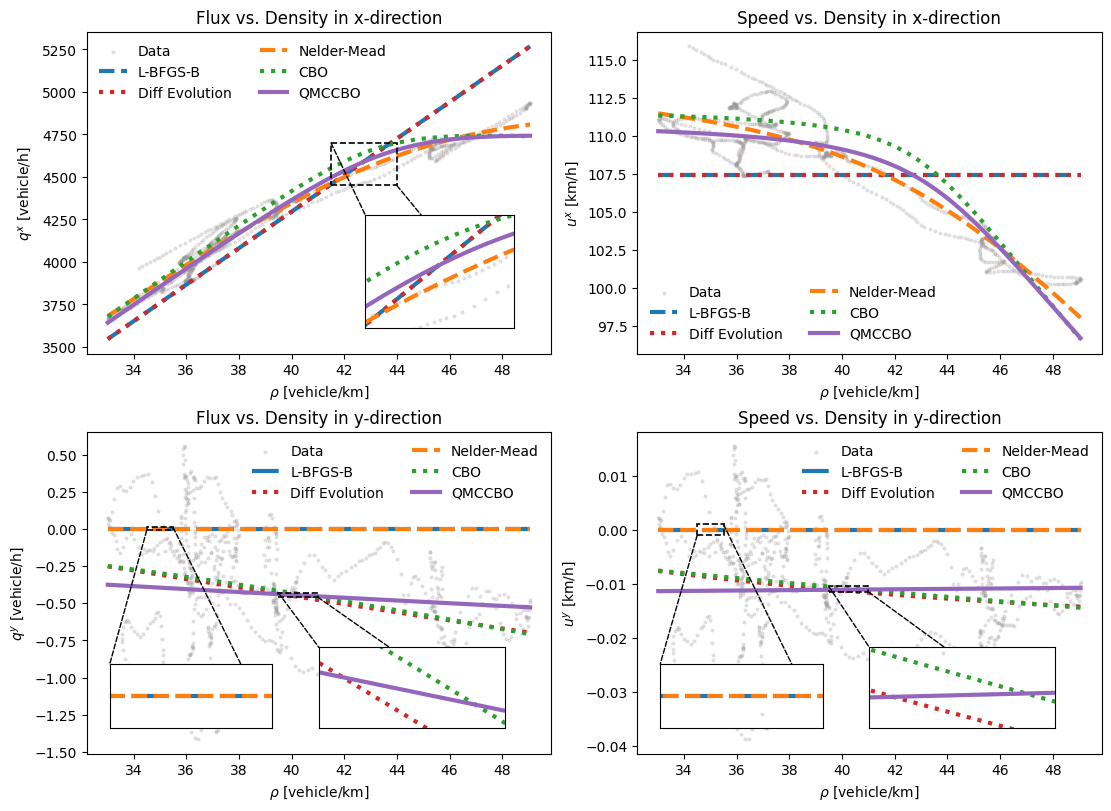

In [ ]:
# plotting fundamental diagrams with fitted models


fig, ax = plt.subplots(2, 2, figsize=(11,8), constrained_layout=True)

# Flux x - directtion
ax[0,0].scatter(rho_data, qx_data, s=4, alpha=alpha_data, color=data_color, label="Data")
ax[0,0].plot(rho_plot, qx_fit_lbfgs, color="#1f77b4", linewidth=lw_main, linestyle="--", label="L-BFGS-B")
ax[0,0].plot(rho_plot, qx_fit_de, color="#d62728", linewidth=lw_other, linestyle=":", label="Diff Evolution")
ax[0,0].plot(rho_plot, qx_fit_simplex, color="#ff7f0e", linewidth=lw_other, linestyle="--", label="Nelder-Mead")
ax[0,0].plot(rho_plot, qx_fit_CBO, color="#2ca02c", linewidth=lw_other, linestyle=":", label="CBO")
ax[0,0].plot(rho_plot, qx_fit_QMCCBO, color="#9467bd", linewidth=lw_other, label="QMCCBO")
ax[0,0].set_title("Flux vs. Density in x-direction")
ax[0,0].set_xlabel(r"$\rho$ [vehicle/km]")
ax[0,0].set_ylabel(r"$q^x$ [vehicle/h]")
ax[0,0].legend(fontsize=10, ncol=2, frameon=False)
add_zoom(ax[0,0], xlim=(41.5,44), ylim=(4450,4700), bbox=(0.60,0.08,0.32,0.35), inset_corners=((0,1), (1,0))) # Zoom

# Speed x-dircetion
ax[0,1].scatter(rho_data, ux_data, s=4, alpha=alpha_data, color=data_color, label="Data")
ax[0,1].plot(rho_plot, u_fit_x_lbfgs, color="#1f77b4", linewidth=lw_main, linestyle="--", label="L-BFGS-B")
ax[0,1].plot(rho_plot, u_fit_x_de, color="#d62728", linewidth=lw_other, linestyle=":", label="Diff Evolution")
ax[0,1].plot(rho_plot, u_fit_x_simplex, color="#ff7f0e", linewidth=lw_other, linestyle="--", label="Nelder-Mead")
ax[0,1].plot(rho_plot, u_fit_x_CBO, color="#2ca02c", linewidth=lw_other, linestyle=":", label="CBO")
ax[0,1].plot(rho_plot, u_fit_x_QMCCBO, color="#9467bd", linewidth=lw_other, label="QMCCBO")
ax[0,1].set_title("Speed vs. Density in x-direction")
ax[0,1].set_xlabel(r"$\rho$ [vehicle/km]")
ax[0,1].set_ylabel(r"$u^x$ [km/h]")
ax[0,1].legend(fontsize=10, ncol=2, frameon=False)
#add_zoom(ax[0,1], xlim=(28,36), ylim=(90,100), bbox=(0.58,0.7,0.35,0.25), inset_corners=((0,1), (1,0))) # Zoom

# Flux y-direction
ax[1,0].scatter(rho_data, qy_data, s=4, alpha=alpha_data, color=data_color, label="Data")
ax[1,0].plot(rho_plot, qy_fit_lbfgs, color="#1f77b4", linewidth=lw_main, linestyle="-.", label="L-BFGS-B")
ax[1,0].plot(rho_plot, qy_fit_de, color="#d62728", linewidth=lw_other, linestyle=":", label="Diff Evolution")
ax[1,0].plot(rho_plot, qy_fit_simplex, color="#ff7f0e", linewidth=lw_other, linestyle="--", label="Nelder-Mead")
ax[1,0].plot(rho_plot, qy_fit_CBO, color="#2ca02c", linewidth=lw_other, linestyle=":", label="CBO")
ax[1,0].plot(rho_plot, qy_fit_QMCCBO, color="#9467bd", linewidth=lw_other, label="QMCCBO")
ax[1,0].set_title("Flux vs. Density in y-direction")
ax[1,0].set_xlabel(r"$\rho$ [vehicle/km]")
ax[1,0].set_ylabel(r"$q^y$ [vehicle/h]")
ax[1,0].legend(fontsize=10, ncol=2, frameon=False)
add_zoom(ax[1,0], xlim=(39.5,41), ylim=(-0.46,-0.43), bbox=(0.50,0.08,0.4,0.25), inset_corners=((0,1), (1,0))) # Zoom
add_zoom(ax[1,0], xlim=(34.5,35.5), ylim=(0.01,-0.01), bbox=(0.05,0.08,0.35,0.2), inset_corners=((0,1), (1,0))) # Zoom

# Speed y-direction
ax[1,1].scatter(rho_data, uy_data, s=4, alpha=alpha_data, color=data_color, label="Data")
ax[1,1].plot(rho_plot, u_fit_y_lbfgs, color="#1f77b4", linewidth=lw_main, linestyle="-.", label="L-BFGS-B")
ax[1,1].plot(rho_plot, u_fit_y_de, color="#d62728", linewidth=lw_other, linestyle=":", label="Diff Evolution")
ax[1,1].plot(rho_plot, u_fit_y_simplex, color="#ff7f0e", linewidth=lw_other, linestyle="--", label="Nelder-Mead")
ax[1,1].plot(rho_plot, u_fit_y_CBO, color="#2ca02c", linewidth=lw_other, linestyle=":", label="CBO")
ax[1,1].plot(rho_plot, u_fit_y_QMCCBO, color="#9467bd",linewidth=lw_other, label="QMCCBO")
ax[1,1].set_title("Speed vs. Density in y-direction")
ax[1,1].set_xlabel(r"$\rho$ [vehicle/km]")
ax[1,1].set_ylabel(r"$u^y$ [km/h]")
ax[1,1].legend(fontsize=10, ncol=2, frameon=False)
add_zoom(ax[1,1], xlim=(39.5,41), ylim=(-0.0115,-0.0105), bbox=(0.50,0.08,0.4,0.25), inset_corners=((0,1), (1,0))) # Zoom
add_zoom(ax[1,1], xlim=(34.5,35.5), ylim=(0.001,-0.001), bbox=(0.05,0.08,0.35,0.2), inset_corners=((0,1), (1,0))) # Zoom

# plt.tight_layout()
plt.savefig("images/fundamental_diagrams_highD_fitted.png", dpi=300, bbox_inches="tight")
plt.show()

In [35]:

qx_fit_de_at_data = qx_model_numpy(rho_data, alpha_x_de, lambda_x_de, p_x_de)
qx_fit_simplex_at_data = qx_model_numpy(rho_data, alpha_x_simplex, lambda_x_simplex, p_x_simplex)
qx_fit_lbfgs_at_data = qx_model_numpy(rho_data, alpha_x_lbfgs, lambda_x_lbfgs, p_x_lbfgs)
qx_fit_CBO_at_data = qx_model_numpy(rho_data, alpha_x_CBO, lambda_x_CBO, p_x_CBO)
qx_fit_QMCCBO_at_data = qx_model_numpy(rho_data, alpha_x_QMCCBO, lambda_x_QMCCBO, p_x_QMCCBO)

err_qx_de = np.linalg.norm(qx_data - qx_fit_de_at_data) / np.linalg.norm(qx_data)
err_qx_simplex = np.linalg.norm(qx_data - qx_fit_simplex_at_data) / np.linalg.norm(qx_data)
err_qx_lbfgs = np.linalg.norm(qx_data - qx_fit_lbfgs_at_data) / np.linalg.norm(qx_data)
err_qx_CBO = np.linalg.norm(qx_data - qx_fit_CBO_at_data) / np.linalg.norm(qx_data)
err_qx_QMCCBO = np.linalg.norm(qx_data - qx_fit_QMCCBO_at_data) / np.linalg.norm(qx_data)

print("Relative L2-errors for qx:\n")

print(f"Differential Evolution : {err_qx_de:.6e}    | time = {time_x_de:.2f} s")
print(f"Nelder-Mead            : {err_qx_simplex:.6e}    | time = {time_x_simplex:.2f} s")
print(f"L-BFGS-B               : {err_qx_lbfgs:.6e}    | time = {time_x_lbfgs:.2f} s")
print(f"CBO                    : {err_qx_CBO:.6e}    | time = {time_x_CBO:.2f} s")
print(f"QMCCBO                 : {err_qx_QMCCBO:.6e}    | time = {time_x_QMCCBO:.2f} s")

Relative L2-errors for qx:

Differential Evolution : 3.808947e-02    | time = 3.67 s
Nelder-Mead            : 1.346195e-02    | time = 0.50 s
L-BFGS-B               : 3.808830e-02    | time = 0.04 s
CBO                    : 1.800780e-02    | time = 0.35 s
QMCCBO                 : 1.574676e-02    | time = 0.30 s


In [37]:
qy_fit_de_at_data = qy_model_numpy(rho_data, alpha_y_de, lambda_y_de, p_y_de)
qy_fit_simplex_at_data = qy_model_numpy(rho_data, alpha_y_simplex, lambda_y_simplex, p_y_simplex)
qy_fit_lbfgs_at_data = qy_model_numpy(rho_data, alpha_y_lbfgs, lambda_y_lbfgs, p_y_lbfgs)
qy_fit_CBO_at_data = qy_model_numpy(rho_data, alpha_y_CBO, lambda_y_CBO, p_y_CBO)
qy_fit_QMCCBO_at_data = qy_model_numpy(rho_data, alpha_y_QMCCBO, lambda_y_QMCCBO, p_y_QMCCBO)

err_qy_de = np.linalg.norm(qy_data - qy_fit_de_at_data) / np.linalg.norm(qy_data)
err_qy_simplex = np.linalg.norm(qy_data - qy_fit_simplex_at_data) / np.linalg.norm(qy_data)
err_qy_lbfgs = np.linalg.norm(qy_data - qy_fit_lbfgs_at_data) / np.linalg.norm(qy_data)
err_qy_CBO = np.linalg.norm(qy_data - qy_fit_CBO_at_data) / np.linalg.norm(qy_data)
err_qy_QMCCBO = np.linalg.norm(qy_data - qy_fit_QMCCBO_at_data) / np.linalg.norm(qy_data)

print("Relative L2-errors for qy:\n")

print(f"Differential Evolution : {err_qy_de:.6e}    | time = {time_y_de:.2f} s")
print(f"Nelder-Mead            : {err_qy_simplex:.6e}    | time = {time_y_simplex:.2f} s")
print(f"L-BFGS-B               : {err_qy_lbfgs:.6e}    | time = {time_y_lbfgs:.2f} s")
print(f"CBO                    : {err_qy_CBO:.6e}    | time = {time_y_CBO:.2f} s")
print(f"QMCCBO                 : {err_qy_QMCCBO:.6e}    | time = {time_y_QMCCBO:.2f} s")

Relative L2-errors for qy:

Differential Evolution : 6.532214e-01    | time = 3.01 s
Nelder-Mead            : 1.000000e+00    | time = 0.11 s
L-BFGS-B               : 1.000000e+00    | time = 0.01 s
CBO                    : 6.540923e-01    | time = 0.36 s
QMCCBO                 : 6.671770e-01    | time = 0.33 s


### Compare all models with data (reduced problem)

In [155]:
# compute fitted data (reduced-problem fits)
# rho_plot already defined above

# Nelder-Mead
qx_fit_simplex_red = qx_model_numpy(rho_plot, alpha_x_simplex_red, lambda_x_simplex_red, p_x_simplex_red)
qy_fit_simplex_red = qy_model_numpy(rho_plot, alpha_y_simplex_red, lambda_y_simplex_red, p_y_simplex_red)

u_fit_x_simplex_red = qx_fit_simplex_red / np.maximum(rho_plot, 1e-6)
u_fit_y_simplex_red = qy_fit_simplex_red / np.maximum(rho_plot, 1e-6)

#L-BFGS-B
qx_fit_lbfgs_red = qx_model_numpy(rho_plot, alpha_x_lbfgs_red, lambda_x_lbfgs_red, p_x_lbfgs_red)
qy_fit_lbfgs_red = qy_model_numpy(rho_plot, alpha_y_lbfgs_red, lambda_y_lbfgs_red, p_y_lbfgs_red)

u_fit_x_lbfgs_red = qx_fit_lbfgs_red / np.maximum(rho_plot, 1e-6)
u_fit_y_lbfgs_red = qy_fit_lbfgs_red / np.maximum(rho_plot, 1e-6)

# Differential Evolution
qx_fit_de_red = qx_model_numpy(rho_plot, alpha_x_de_red, lambda_x_de_red, p_x_de_red)
qy_fit_de_red = qy_model_numpy(rho_plot, alpha_y_de_red, lambda_y_de_red, p_y_de_red)

u_fit_x_de_red = qx_fit_de_red / np.maximum(rho_plot, 1e-6)
u_fit_y_de_red = qy_fit_de_red / np.maximum(rho_plot, 1e-6)

# CBO
qx_fit_CBO_red = qx_model_numpy(rho_plot, alpha_x_CBO_red, lambda_x_CBO_red, p_x_CBO_red)
qy_fit_CBO_red = qy_model_numpy(rho_plot, alpha_y_CBO_red, lambda_y_CBO_red, p_y_CBO_red)

u_fit_x_CBO_red = qx_fit_CBO_red / np.maximum(rho_plot, 1e-6)
u_fit_y_CBO_red = qy_fit_CBO_red / np.maximum(rho_plot, 1e-6)

# QMCCBO
qx_fit_QMCCBO_red = qx_model_numpy(rho_plot, alpha_x_QMCCBO_red, lambda_x_QMCCBO_red, p_x_QMCCBO_red)
qy_fit_QMCCBO_red = qy_model_numpy(rho_plot, alpha_y_QMCCBO_red, lambda_y_QMCCBO_red, p_y_QMCCBO_red)

u_fit_x_QMCCBO_red = qx_fit_QMCCBO_red / np.maximum(rho_plot, 1e-6)
u_fit_y_QMCCBO_red = qy_fit_QMCCBO_red / np.maximum(rho_plot, 1e-6)

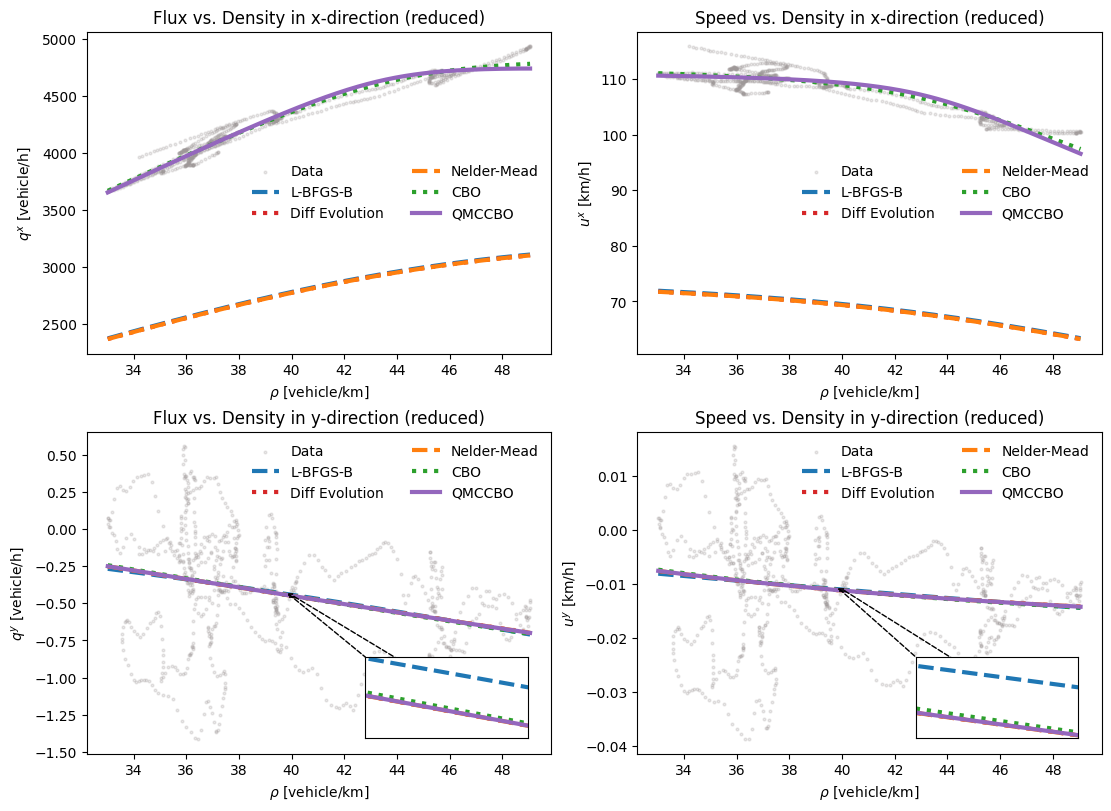

In [ ]:
# plotting fundamental diagrams with fitted models (reduced-problem fits)
# reuses the add_zoom(...) helper defined above

fig, ax = plt.subplots(2, 2, figsize=(11,8), constrained_layout=True)

# Flux x-direction
ax[0,0].scatter(rho_data, qx_data, s=4, alpha=alpha_data, color=data_color, label="Data")
ax[0,0].plot(rho_plot, qx_fit_lbfgs_red, color="#1f77b4", linewidth=lw_main, linestyle="--", label="L-BFGS-B")
ax[0,0].plot(rho_plot, qx_fit_de_red, color="#d62728", linewidth=lw_other, linestyle=":", label="Diff Evolution")
ax[0,0].plot(rho_plot, qx_fit_simplex_red, color="#ff7f0e", linewidth=lw_other, linestyle="--", label="Nelder-Mead")
ax[0,0].plot(rho_plot, qx_fit_CBO_red, color="#2ca02c", linewidth=lw_other, linestyle=":", label="CBO")
ax[0,0].plot(rho_plot, qx_fit_QMCCBO_red, color="#9467bd", linewidth=lw_other, label="QMCCBO")
ax[0,0].set_title("Flux vs. Density in x-direction (reduced)")
ax[0,0].set_xlabel(r"$\rho$ [vehicle/km]")
ax[0,0].set_ylabel(r"$q^x$ [vehicle/h]")
ax[0,0].legend(fontsize=10, ncol=2, frameon=False)
#add_zoom(ax[0,0], xlim=(36,38), ylim=(3255,3275), bbox=(0.50,0.28,0.35,0.25), inset_corners=((0,1), (1,0))) # Zoom

# Speed x-direction
ax[0,1].scatter(rho_data, ux_data, s=4, alpha=alpha_data, color=data_color, label="Data")
ax[0,1].plot(rho_plot, u_fit_x_lbfgs_red, color="#1f77b4", linewidth=lw_main, linestyle="--", label="L-BFGS-B")
ax[0,1].plot(rho_plot, u_fit_x_de_red, color="#d62728", linewidth=lw_other, linestyle=":", label="Diff Evolution")
ax[0,1].plot(rho_plot, u_fit_x_simplex_red, color="#ff7f0e", linewidth=lw_other, linestyle="--", label="Nelder-Mead")
ax[0,1].plot(rho_plot, u_fit_x_CBO_red, color="#2ca02c", linewidth=lw_other, linestyle=":", label="CBO")
ax[0,1].plot(rho_plot, u_fit_x_QMCCBO_red, color="#9467bd", linewidth=lw_other, label="QMCCBO")
ax[0,1].set_title("Speed vs. Density in x-direction (reduced)")
ax[0,1].set_xlabel(r"$\rho$ [vehicle/km]")
ax[0,1].set_ylabel(r"$u^x$ [km/h]")
ax[0,1].legend(fontsize=10, ncol=2, frameon=False)
#add_zoom(ax[0,1], xlim=(28,36), ylim=(90,100), bbox=(0.58,0.7,0.35,0.25), inset_corners=((0,1), (1,0))) # Zoom

# Flux y-direction
ax[1,0].scatter(rho_data, qy_data, s=4, alpha=alpha_data, color=data_color, label="Data")
ax[1,0].plot(rho_plot, qy_fit_lbfgs_red, color="#1f77b4", linewidth=lw_main, linestyle="--", label="L-BFGS-B")
ax[1,0].plot(rho_plot, qy_fit_de_red, color="#d62728", linewidth=lw_other, linestyle=":", label="Diff Evolution")
ax[1,0].plot(rho_plot, qy_fit_simplex_red, color="#ff7f0e", linewidth=lw_other, linestyle="--", label="Nelder-Mead")
ax[1,0].plot(rho_plot, qy_fit_CBO_red, color="#2ca02c", linewidth=lw_other, linestyle=":", label="CBO")
ax[1,0].plot(rho_plot, qy_fit_QMCCBO_red, color="#9467bd", linewidth=lw_other, label="QMCCBO")
ax[1,0].set_title("Flux vs. Density in y-direction (reduced)")
ax[1,0].set_xlabel(r"$\rho$ [vehicle/km]")
ax[1,0].set_ylabel(r"$q^y$ [vehicle/h]")
ax[1,0].legend(fontsize=10, ncol=2, frameon=False)
add_zoom(ax[1,0], xlim=(39.9,40.1), ylim=(-0.455,-0.44), bbox=(0.6,0.05,0.35,0.25), inset_corners=((0,1), (1,0))) # Zoom

# Speed y-direction
ax[1,1].scatter(rho_data, uy_data, s=4, alpha=alpha_data, color=data_color, label="Data")
ax[1,1].plot(rho_plot, u_fit_y_lbfgs_red, color="#1f77b4", linewidth=lw_main, linestyle="--", label="L-BFGS-B")
ax[1,1].plot(rho_plot, u_fit_y_de_red, color="#d62728", linewidth=lw_other, linestyle=":", label="Diff Evolution")
ax[1,1].plot(rho_plot, u_fit_y_simplex_red, color="#ff7f0e", linewidth=lw_other, linestyle="--", label="Nelder-Mead")
ax[1,1].plot(rho_plot, u_fit_y_CBO_red, color="#2ca02c", linewidth=lw_other, linestyle=":", label="CBO")
ax[1,1].plot(rho_plot, u_fit_y_QMCCBO_red, color="#9467bd", linewidth=lw_other, label="QMCCBO")
ax[1,1].set_title("Speed vs. Density in y-direction (reduced)")
ax[1,1].set_xlabel(r"$\rho$ [vehicle/km]")
ax[1,1].set_ylabel(r"$u^y$ [km/h]")
ax[1,1].legend(fontsize=10, ncol=2, frameon=False)
add_zoom(ax[1,1], xlim=(39.9,40.1), ylim=(-0.0113,-0.011), bbox=(0.6,0.05,0.35,0.25), inset_corners=((0,1), (1,0))) # Zoom

# plt.tight_layout()
plt.savefig("images/fundamental_diagrams_highD_fitted_reduced.png", dpi=300, bbox_inches="tight")
plt.show()

In [123]:
qx_fit_de_at_data_red = qx_model_numpy(rho_data, alpha_x_de_red, lambda_x_de_red, p_x_de_red)
qx_fit_simplex_at_data_red = qx_model_numpy(rho_data, alpha_x_simplex_red, lambda_x_simplex_red, p_x_simplex_red)
qx_fit_lbfgs_at_data_red = qx_model_numpy(rho_data, alpha_x_lbfgs_red, lambda_x_lbfgs_red, p_x_lbfgs_red)
qx_fit_CBO_at_data_red = qx_model_numpy(rho_data, alpha_x_CBO_red, lambda_x_CBO_red, p_x_CBO_red)
qx_fit_QMCCBO_at_data_red = qx_model_numpy(rho_data, alpha_x_QMCCBO_red, lambda_x_QMCCBO_red, p_x_QMCCBO_red)

err_qx_de_red = np.linalg.norm(qx_data - qx_fit_de_at_data_red) / np.linalg.norm(qx_data)
err_qx_simplex_red = np.linalg.norm(qx_data - qx_fit_simplex_at_data_red) / np.linalg.norm(qx_data)
err_qx_lbfgs_red = np.linalg.norm(qx_data - qx_fit_lbfgs_at_data_red) / np.linalg.norm(qx_data)
err_qx_CBO_red = np.linalg.norm(qx_data - qx_fit_CBO_at_data_red) / np.linalg.norm(qx_data)
err_qx_QMCCBO_red = np.linalg.norm(qx_data - qx_fit_QMCCBO_at_data_red) / np.linalg.norm(qx_data)

print("Relative L2-errors for qx (reduced problem):\n")

print(f"Differential Evolution : {err_qx_de_red:.6e}    | time = {time_x_de_red:.2f} s")
print(f"Nelder-Mead            : {err_qx_simplex_red:.6e}    | time = {time_x_simplex_red:.2f} s")
print(f"L-BFGS-B               : {err_qx_lbfgs_red:.6e}    | time = {time_x_lbfgs_red:.2f} s")
print(f"CBO                    : {err_qx_CBO_red:.6e}    | time = {time_x_CBO_red:.2f} s")
print(f"QMCCBO                 : {err_qx_QMCCBO_red:.6e}    | time = {time_x_QMCCBO_red:.2f} s")

Relative L2-errors for qx (reduced problem):

Differential Evolution : 3.599388e-01    | time = 0.94 s
Nelder-Mead            : 3.598730e-01    | time = 0.34 s
L-BFGS-B               : 3.582036e-01    | time = 0.11 s
CBO                    : 2.218684e-01    | time = 0.10 s
QMCCBO                 : 1.556927e-02    | time = 0.09 s


In [124]:
qy_fit_de_at_data_red = qy_model_numpy(rho_data, alpha_y_de_red, lambda_y_de_red, p_y_de_red)
qy_fit_simplex_at_data_red = qy_model_numpy(rho_data, alpha_y_simplex_red, lambda_y_simplex_red, p_y_simplex_red)
qy_fit_lbfgs_at_data_red = qy_model_numpy(rho_data, alpha_y_lbfgs_red, lambda_y_lbfgs_red, p_y_lbfgs_red)
qy_fit_CBO_at_data_red = qy_model_numpy(rho_data, alpha_y_CBO_red, lambda_y_CBO_red, p_y_CBO_red)
qy_fit_QMCCBO_at_data_red = qy_model_numpy(rho_data, alpha_y_QMCCBO_red, lambda_y_QMCCBO_red, p_y_QMCCBO_red)

err_qy_de_red = np.linalg.norm(qy_data - qy_fit_de_at_data_red) / np.linalg.norm(qy_data)
err_qy_simplex_red = np.linalg.norm(qy_data - qy_fit_simplex_at_data_red) / np.linalg.norm(qy_data)
err_qy_lbfgs_red = np.linalg.norm(qy_data - qy_fit_lbfgs_at_data_red) / np.linalg.norm(qy_data)
err_qy_CBO_red = np.linalg.norm(qy_data - qy_fit_CBO_at_data_red) / np.linalg.norm(qy_data)
err_qy_QMCCBO_red = np.linalg.norm(qy_data - qy_fit_QMCCBO_at_data_red) / np.linalg.norm(qy_data)

print("Relative L2-errors for qy (reduced problem):\n")

print(f"Differential Evolution : {err_qy_de_red:.6e}    | time = {time_y_de_red:.2f} s")
print(f"Nelder-Mead            : {err_qy_simplex_red:.6e}    | time = {time_y_simplex_red:.2f} s")
print(f"L-BFGS-B               : {err_qy_lbfgs_red:.6e}    | time = {time_y_lbfgs_red:.2f} s")
print(f"CBO                    : {err_qy_CBO_red:.6e}    | time = {time_y_CBO_red:.2f} s")
print(f"QMCCBO                 : {err_qy_QMCCBO_red:.6e}    | time = {time_y_QMCCBO_red:.2f} s")

Relative L2-errors for qy (reduced problem):

Differential Evolution : 6.532189e-01    | time = 0.54 s
Nelder-Mead            : 6.532189e-01    | time = 0.18 s
L-BFGS-B               : 6.536462e-01    | time = 0.03 s
CBO                    : 6.533908e-01    | time = 0.09 s
QMCCBO                 : 6.532192e-01    | time = 0.07 s
